[INFO] device = cuda
[INFO] hidden_dims = [256, 512, 256]
[INFO] max_n in test = 132
[INFO] Loaded model: best_model_in4_K4_256-512-256_testloss0.051024.pth
[INFO] Number of test samples = 500


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_23352\327582938.py:632: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


[INFO] Mean absolute error on test set:
  Mean x1      : 0.005579
  Mean x2      : 0.006885
  Covariance   : 0.016143
[SAVED] compare_test_scatter_one_row_sci.pdf


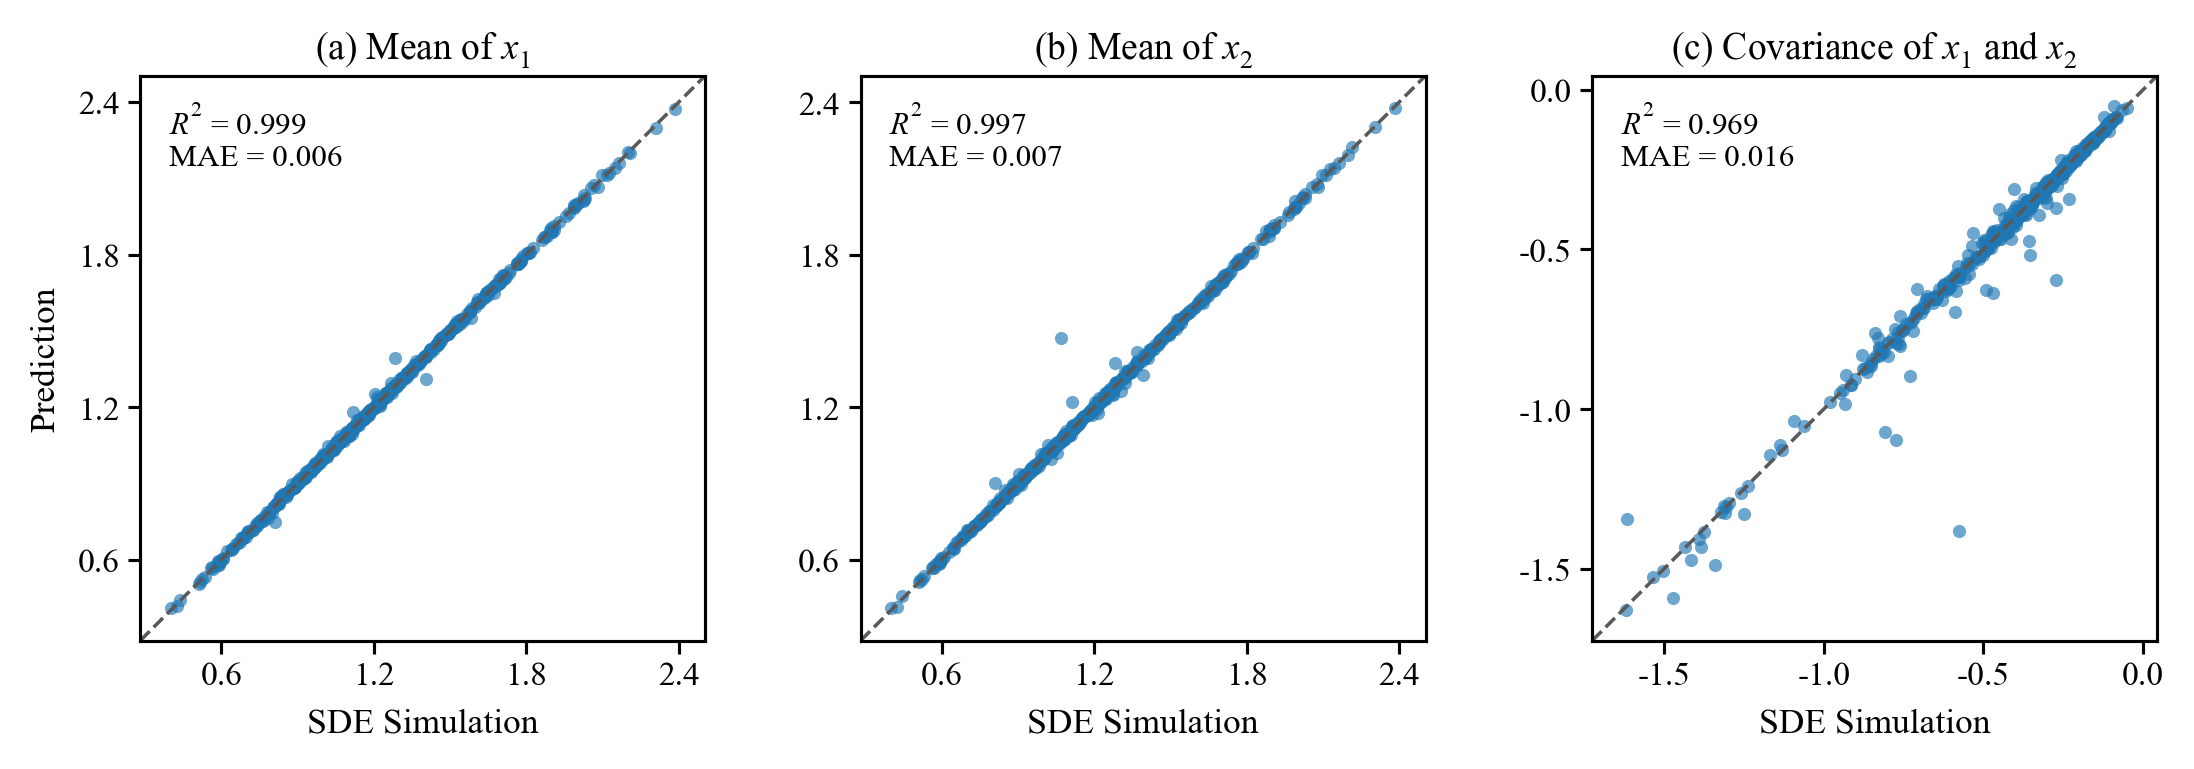

[DONE] Test-set one-row SCI-style scatter figure finished.


In [3]:
# compare_test_mean_covariance_one_row_paper_sci.py
import os
import argparse
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from torch.utils.data import Dataset, DataLoader
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
def set_paper_style():
    # 字体：英文和数字使用 Times New Roman
    plt.rcParams["font.family"] = "Times New Roman"
    plt.rcParams["font.serif"] = ["Times New Roman"]

    # 数学字体尽量贴近 Times New Roman
    plt.rcParams["mathtext.fontset"] = "custom"
    plt.rcParams["mathtext.rm"] = "Times New Roman"
    plt.rcParams["mathtext.it"] = "Times New Roman:italic"
    plt.rcParams["mathtext.bf"] = "Times New Roman:bold"

    # PDF 字体嵌入，方便 CorelDRAW / Illustrator 后期编辑
    plt.rcParams["pdf.fonttype"] = 42
    plt.rcParams["ps.fonttype"] = 42

    # 字号：适合 SCI 论文图
    plt.rcParams["font.size"] = 8.5
    plt.rcParams["axes.labelsize"] = 8.5
    plt.rcParams["axes.titlesize"] = 9
    plt.rcParams["xtick.labelsize"] = 8
    plt.rcParams["ytick.labelsize"] = 8
    plt.rcParams["legend.fontsize"] = 8

    # 坐标轴和刻度线宽
    plt.rcParams["axes.linewidth"] = 0.75
    plt.rcParams["xtick.major.width"] = 0.75
    plt.rcParams["ytick.major.width"] = 0.75
    plt.rcParams["xtick.major.size"] = 3.0
    plt.rcParams["ytick.major.size"] = 3.0

    # 刻度朝外
    plt.rcParams["xtick.direction"] = "out"
    plt.rcParams["ytick.direction"] = "out"

    # 负号正常显示
    plt.rcParams["axes.unicode_minus"] = False

    # 保存分辨率
    plt.rcParams["figure.dpi"] = 300
    plt.rcParams["savefig.dpi"] = 600


# ============================================================
# 1. 模型定义
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=4, num_components=4, hidden_dims=None):
        super().__init__()

        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError("hidden_dims 不能为空，且需至少包含一层。")

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        self.hidden_layers = nn.ModuleList()
        self.hidden_layers.append(nn.Linear(input_dim, hidden_dims[0]))

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(hidden_dims[i - 1], hidden_dims[i])
            )

        # 每个二维高斯成分输出 6 个参数
        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, x):
        B = x.shape[0]

        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        out = self.output_layer(x).view(B, self.num_components, 6)

        # 混合权重
        weights = F.softmax(out[:, :, 0], dim=1)

        # 均值，形状为 [B, K, 2]
        means = out[:, :, 1:3]

        eps = 1e-6

        # 协方差矩阵参数
        s_xx = F.softplus(out[:, :, 3]) + eps

        alpha = out[:, :, 4]
        rho = 2 * torch.sigmoid(alpha) - 1
        rho = torch.clamp(rho, -1 + 1e-4, 1 - 1e-4)

        s_yy = F.softplus(out[:, :, 5]) + eps
        s_xy = rho * torch.sqrt(s_xx * s_yy)

        covs = torch.zeros(
            B,
            self.num_components,
            2,
            2,
            device=x.device
        )

        covs[:, :, 0, 0] = s_xx
        covs[:, :, 0, 1] = s_xy
        covs[:, :, 1, 0] = s_xy
        covs[:, :, 1, 1] = s_yy

        return weights, means, covs


# ============================================================
# 2. 工具函数
# ============================================================
def mat_name(prefix: str, idx0: int, suffix: str = ".mat") -> str:
    """
    生成 mat 文件名，例如：
    ps_test{1}.mat
    ps_test{2}.mat
    """
    return f"{prefix}{{{idx0 + 1}}}{suffix}"


def find_max_n_in_dir(mat_dir: str, prefix="ps_test", suffix=".mat") -> int:
    """
    在测试集 mat 文件夹中寻找最大的密度矩阵尺寸。
    """
    max_n = 0

    for fn in os.listdir(mat_dir):
        if fn.startswith(prefix) and fn.endswith(suffix):
            mat_path = os.path.join(mat_dir, fn)
            d = loadmat(mat_path).get("density", None)

            if d is None:
                raise KeyError(f"'density' 未在 {fn} 中找到")

            max_n = max(max_n, int(d.shape[0]))

    if max_n <= 0:
        raise RuntimeError(
            f"在目录 {mat_dir} 没找到符合 {prefix}*{suffix} 的文件"
        )

    return max_n


def build_grid(max_n: int, edge: float, device: torch.device):
    """
    根据密度矩阵大小和网格步长构建二维网格。
    edge=0.05 时，网格中心为：
    0.025, 0.075, 0.125, ...
    """
    lim = max_n * edge

    centers = torch.linspace(
        edge / 2,
        lim - edge / 2,
        steps=max_n,
        device=device
    )

    grid_x, grid_y = torch.meshgrid(
        centers,
        centers,
        indexing="ij"
    )

    return grid_x, grid_y


@torch.no_grad()
def mog_density_on_grid(weights, means, covs, grid_x, grid_y, eps=1e-8):
    """
    将模型输出的二维高斯混合参数转换为网格上的预测概率密度矩阵。
    """
    B, K = weights.shape

    mu_x = means[:, :, 0].unsqueeze(-1).unsqueeze(-1)
    mu_y = means[:, :, 1].unsqueeze(-1).unsqueeze(-1)

    s_xx = covs[:, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
    s_xy = covs[:, :, 0, 1].unsqueeze(-1).unsqueeze(-1)
    s_yy = covs[:, :, 1, 1].unsqueeze(-1).unsqueeze(-1)

    det = s_xx * s_yy - s_xy ** 2
    det = torch.clamp(det, min=1e-12)

    inv_xx = s_yy / det
    inv_xy = -s_xy / det
    inv_yy = s_xx / det

    gx = grid_x.unsqueeze(0).unsqueeze(0)
    gy = grid_y.unsqueeze(0).unsqueeze(0)

    dx = gx - mu_x
    dy = gy - mu_y

    exponent = -0.5 * (
        inv_xx * dx ** 2
        + 2 * inv_xy * dx * dy
        + inv_yy * dy ** 2
    )

    gaussian = (
        1.0 / (2 * torch.pi * torch.sqrt(det))
    ) * torch.exp(exponent)

    w = weights.unsqueeze(-1).unsqueeze(-1)

    pred = torch.sum(w * gaussian, dim=1)

    pred = pred + eps
    pred = pred / pred.sum(dim=[1, 2], keepdim=True)

    return pred


def normalize_density(d, eps=1e-8):
    """
    将密度矩阵归一化，使矩阵元素和为 1。
    """
    d = d + eps
    d = d / d.sum(dim=[1, 2], keepdim=True)

    return d


def mean_cov_2d(d, grid_x, grid_y):
    """
    计算二维概率密度矩阵的 x1 均值、x2 均值和 Cov(x1,x2)。

    返回：
    mean_x1, mean_x2, cov_x1x2
    """
    B = d.shape[0]

    gx = grid_x.unsqueeze(0).expand(B, -1, -1)
    gy = grid_y.unsqueeze(0).expand(B, -1, -1)

    mean_x1 = (d * gx).sum(dim=[1, 2])
    mean_x2 = (d * gy).sum(dim=[1, 2])

    cov_x1x2 = (
        d
        * (gx - mean_x1[:, None, None])
        * (gy - mean_x2[:, None, None])
    ).sum(dim=[1, 2])

    return mean_x1, mean_x2, cov_x1x2


def calc_r2_mae(true_vals, pred_vals):
    """
    计算 R2 和 MAE。
    """
    true_vals = np.asarray(true_vals)
    pred_vals = np.asarray(pred_vals)

    mae = np.mean(np.abs(true_vals - pred_vals))

    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - np.mean(true_vals)) ** 2)

    if ss_tot < 1e-12:
        r2 = np.nan
    else:
        r2 = 1.0 - ss_res / ss_tot

    return r2, mae


# ============================================================
# 3. 测试集 Dataset
# ============================================================
class TestDataset(Dataset):
    def __init__(
        self,
        csv_file,
        mat_dir,
        max_n,
        input_dim=4,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    ):
        self.df = pd.read_csv(csv_file)
        self.mat_dir = mat_dir
        self.max_n = int(max_n)
        self.input_dim = int(input_dim)
        self.mat_prefix = mat_prefix
        self.mat_suffix = mat_suffix

        if self.df.shape[1] < self.input_dim:
            raise ValueError(
                f"CSV列数={self.df.shape[1]} < input_dim={self.input_dim}"
            )

        expected = len(self.df)

        actual = len([
            f for f in os.listdir(mat_dir)
            if f.startswith(mat_prefix) and f.endswith(mat_suffix)
        ])

        if actual != expected:
            raise ValueError(
                f"CSV样本数({expected}) 与 mat文件数({actual}) 不匹配"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # 读取输入参数，例如 a, b, k, D
        x = self.df.iloc[idx, :self.input_dim].values.astype(np.float32)
        x = torch.tensor(x, dtype=torch.float32)

        # 读取测试集真实密度矩阵
        fn = mat_name(
            self.mat_prefix,
            idx,
            self.mat_suffix
        )

        mp = os.path.join(self.mat_dir, fn)

        mat = loadmat(mp)
        d = mat.get("density", None)

        if d is None:
            raise KeyError(f"'density' 未在 {mp} 中找到")

        d = torch.tensor(d.astype(np.float32))

        # pad 到统一大小
        n = d.shape[0]
        pad = self.max_n - n

        if pad > 0:
            d = F.pad(
                d,
                (0, pad, 0, pad),
                mode="constant",
                value=0.0
            )

        return x, d


# ============================================================
# 4. 三张图横向放一起：SCI 论文风格
# ============================================================
def scatter_three_panels_row(
    true_mx,
    pred_mx,
    true_my,
    pred_my,
    true_cxy,
    pred_cxy,
    out_path,
    xlabel="SDE Simulation",
    ylabel="Prediction",
    show=True
):
    """
    横向画三张论文风格散点图：
    (a) Mean of x1
    (b) Mean of x2
    (c) Covariance of x1 and x2
    """
    set_paper_style()

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(7.4, 2.45),
        dpi=300,
        constrained_layout=True
    )

    plot_items = [
        (true_mx, pred_mx, r"(a) Mean of $x_1$"),
        (true_my, pred_my, r"(b) Mean of $x_2$"),
        (true_cxy, pred_cxy, r"(c) Covariance of $x_1$ and $x_2$")
    ]

    for ax, (true_vals, pred_vals, title) in zip(axes, plot_items):
        true_vals = np.asarray(true_vals)
        pred_vals = np.asarray(pred_vals)

        # 散点：黑色，透明度适中，适合黑白打印和论文排版
        ax.scatter(
            true_vals,
            pred_vals,
            s=10,
            alpha=0.65,
            c="#1f77b4",
            linewidths=0
        )

        # 坐标范围
        mn = float(min(true_vals.min(), pred_vals.min()))
        mx = float(max(true_vals.max(), pred_vals.max()))

        margin = 0.06 * (mx - mn) if mx > mn else 0.05
        mn_plot = mn - margin
        mx_plot = mx + margin

        # y = x 参考线
        ax.plot(
            [mn_plot, mx_plot],
            [mn_plot, mx_plot],
            linestyle="--",
            linewidth=0.85,
            color="0.35"
        )

        ax.set_xlim(mn_plot, mx_plot)
        ax.set_ylim(mn_plot, mx_plot)

        # 保证 y=x 是 45 度
        ax.set_aspect("equal", adjustable="box")
        ax.set_box_aspect(1)

        # 标题和坐标轴
        ax.set_title(title, pad=4)
        ax.set_xlabel(xlabel)

        # 为了节省横向空间，只在第一张图保留 y 轴标签
        if ax is axes[0]:
            ax.set_ylabel(ylabel)
        else:
            ax.set_ylabel("")

        # 统一坐标轴线宽
        for spine in ax.spines.values():
            spine.set_linewidth(0.75)

        # 统一刻度线宽和长度
        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=3,
            width=0.75,
            pad=2
        )

        # 控制刻度数量，避免过密
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

        # 添加 R2 和 MAE
        r2, mae = calc_r2_mae(true_vals, pred_vals)

        text_str = (
            r"$R^2$ = " + f"{r2:.3f}\n"
            + "MAE = " + f"{mae:.3f}"
        )

        ax.text(
            0.05,
            0.95,
            text_str,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.5
        )

    # 保存 PDF
    fig.savefig(
        out_path,
        format="pdf",
        bbox_inches="tight"
    )

    print(f"[SAVED] {out_path}")

    if show:
        plt.show()

    plt.close(fig)


# ============================================================
# 5. 主程序：在测试集上画横向三联图
# ============================================================
def main():
    ap = argparse.ArgumentParser()

    # 测试集 CSV
    ap.add_argument(
        "--csv_test",
        type=str,
        default="ps_test.csv"
    )

    # 测试集密度矩阵文件夹
    ap.add_argument(
        "--mat_test_dir",
        type=str,
        default="density_results_ps_test_n_cells=50000_edges=0.05"
    )

    # 已训练好的模型路径
    ap.add_argument(
        "--model_path",
        type=str,
        default="best_model_in4_K4_256-512-256_testloss0.051024.pth"
    )

    ap.add_argument(
        "--input_dim",
        type=int,
        default=4
    )

    ap.add_argument(
        "--num_components",
        type=int,
        default=4
    )

    ap.add_argument(
        "--hidden_dims",
        type=str,
        default="256,512,256"
    )

    ap.add_argument(
        "--edge",
        type=float,
        default=0.05
    )

    ap.add_argument(
        "--batch_size",
        type=int,
        default=8
    )

    ap.add_argument(
        "--num_workers",
        type=int,
        default=0
    )

    # 输出 PDF 文件名
    ap.add_argument(
        "--out_pdf",
        type=str,
        default="compare_test_scatter_one_row_sci.pdf"
    )

    # 默认展示图片；如果命令行加 --no_show，则只保存不展示
    ap.add_argument(
        "--no_show",
        action="store_true"
    )

    # 兼容 Jupyter 自动注入的 -f 参数
    args, _ = ap.parse_known_args()

    show_fig = not args.no_show

    # ------------------------------------------------------------
    # 设备
    # ------------------------------------------------------------
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print(f"[INFO] device = {device}")

    # ------------------------------------------------------------
    # 隐藏层结构
    # ------------------------------------------------------------
    hidden_dims = [
        int(x)
        for x in args.hidden_dims.split(",")
        if x.strip()
    ]

    print(f"[INFO] hidden_dims = {hidden_dims}")

    # ------------------------------------------------------------
    # 找测试集中最大的密度矩阵尺寸
    # ------------------------------------------------------------
    max_n = find_max_n_in_dir(
        args.mat_test_dir,
        prefix="ps_test",
        suffix=".mat"
    )

    print(f"[INFO] max_n in test = {max_n}")

    # ------------------------------------------------------------
    # 构建二维网格
    # ------------------------------------------------------------
    grid_x, grid_y = build_grid(
        max_n=max_n,
        edge=args.edge,
        device=device
    )

    # ------------------------------------------------------------
    # 加载模型
    # ------------------------------------------------------------
    model = MixtureOfGaussiansModel(
        input_dim=args.input_dim,
        num_components=args.num_components,
        hidden_dims=hidden_dims
    ).to(device)

    model.load_state_dict(
        torch.load(
            args.model_path,
            map_location=device
        )
    )

    model.eval()

    print(f"[INFO] Loaded model: {args.model_path}")

    # ------------------------------------------------------------
    # 加载测试集
    # ------------------------------------------------------------
    ds = TestDataset(
        csv_file=args.csv_test,
        mat_dir=args.mat_test_dir,
        max_n=max_n,
        input_dim=args.input_dim,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    )

    dl = DataLoader(
        ds,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=args.num_workers
    )

    print(f"[INFO] Number of test samples = {len(ds)}")

    # ------------------------------------------------------------
    # 存储真实与预测的 x1 均值、x2 均值、协方差
    # ------------------------------------------------------------
    true_mx, true_my, true_cxy = [], [], []
    pred_mx, pred_my, pred_cxy = [], [], []

    # ------------------------------------------------------------
    # 在测试集上预测
    # ------------------------------------------------------------
    with torch.no_grad():
        for xb, db in dl:
            xb = xb.to(device)
            db = db.to(device)

            # 真实密度归一化
            true = normalize_density(db)

            # 模型预测
            w, m, c = model(xb)

            pred = mog_density_on_grid(
                w,
                m,
                c,
                grid_x,
                grid_y
            )

            # 计算真实分布的 x1 均值、x2 均值、协方差
            t_mx, t_my, t_cxy = mean_cov_2d(
                true,
                grid_x,
                grid_y
            )

            # 计算预测分布的 x1 均值、x2 均值、协方差
            p_mx, p_my, p_cxy = mean_cov_2d(
                pred,
                grid_x,
                grid_y
            )

            true_mx.append(t_mx.cpu().numpy())
            true_my.append(t_my.cpu().numpy())
            true_cxy.append(t_cxy.cpu().numpy())

            pred_mx.append(p_mx.cpu().numpy())
            pred_my.append(p_my.cpu().numpy())
            pred_cxy.append(p_cxy.cpu().numpy())

    # ------------------------------------------------------------
    # 拼接所有 batch
    # ------------------------------------------------------------
    true_mx = np.concatenate(true_mx)
    true_my = np.concatenate(true_my)
    true_cxy = np.concatenate(true_cxy)

    pred_mx = np.concatenate(pred_mx)
    pred_my = np.concatenate(pred_my)
    pred_cxy = np.concatenate(pred_cxy)

    # ------------------------------------------------------------
    # 输出简单误差信息
    # ------------------------------------------------------------
    print("[INFO] Mean absolute error on test set:")
    print(f"  Mean x1      : {np.mean(np.abs(true_mx - pred_mx)):.6f}")
    print(f"  Mean x2      : {np.mean(np.abs(true_my - pred_my)):.6f}")
    print(f"  Covariance   : {np.mean(np.abs(true_cxy - pred_cxy)):.6f}")

    # ------------------------------------------------------------
    # 画测试集横向三联图并保存为 PDF
    # ------------------------------------------------------------
    scatter_three_panels_row(
        true_mx,
        pred_mx,
        true_my,
        pred_my,
        true_cxy,
        pred_cxy,
        out_path=args.out_pdf,
        xlabel="SDE Simulation",
        ylabel="Prediction",
        show=show_fig
    )

    print("[DONE] Test-set one-row SCI-style scatter figure finished.")


if __name__ == "__main__":
    main()